In [1]:
%matplotlib inline
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from xgboost import XGBClassifier

from clean_mission1 import OUT_DIR
from features_mission1 import iter_features, load_training_table
from label_mission1 import HORIZONS, MAIN_CLASSES, folds, load_labels
from evaluate_mission1 import evaluate, pool

labels = load_labels()
events = pd.read_csv(f'{OUT_DIR}/events.csv', index_col='ID', parse_dates=['onset', 'end'])
train_X = load_training_table(labels)
SCORE_DIR = f'{OUT_DIR}/scores'
os.makedirs(SCORE_DIR, exist_ok=True)
print(f'training table {train_X.shape}, positives (5/15/30 min): '
      f'{[int(labels[f"y_{h}"].reindex(train_X.index).sum()) for h in HORIZONS]}')

training table (137959, 456), positives (5/15/30 min): [1090, 3270, 6540]


In [2]:
# Hyperparameters are fixed in advance: the calibration years hold too few anomalies to tune on.
PARAMS = dict(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.5,
              tree_method='hist', n_jobs=-1, random_state=0)


def fit(fold, h):
    X = train_X.loc[fold['train'][0]:fold['train'][1]]
    return XGBClassifier(**PARAMS).fit(X, labels[f'y_{h}'].reindex(X.index))


def deviation(f, scale):
    """Label-free detector: largest current deviation of any channel from its own 60-min mean, in training stds."""
    return (f.filter(like='_dev60').abs() / scale).max(axis=1)


def full_length(s):
    out = np.full(len(labels), np.nan, np.float32)
    lo = labels.index.searchsorted(s.index[0])
    out[lo:lo + len(s)] = s.to_numpy()
    return out

In [3]:
# One XGBoost model per fold and horizon; score every 30s step of the fold's calibration and test years.
# If the deviation detector does as well as XGBoost, the models are mostly catching anomalies already under way.
results = {'xgboost': ([], []), 'deviation': ([], [])}
for fold in folds():
    models = {h: fit(fold, h) for h in HORIZONS}
    scale = train_X.loc[fold['train'][0]:fold['train'][1]].filter(like='_dev60').std().replace(0, np.nan)
    scored = pd.concat(
        pd.DataFrame({**{f'xgboost_{h}': m.predict_proba(f)[:, 1] for h, m in models.items()},
                      'deviation': deviation(f, scale)}, index=f.index)
        for f in iter_features(fold['calib'][0], fold['test'][1]))
    scored.to_parquet(f'{SCORE_DIR}/{fold["name"]}.parquet')

    for h in HORIZONS:
        e, s = evaluate(full_length(scored[f'xgboost_{h}']), labels, events, fold, horizons=[h])
        results['xgboost'][0].append(e)
        results['xgboost'][1].append(s)
    e, s = evaluate(full_length(scored.deviation), labels, events, fold)
    results['deviation'][0].append(e)
    results['deviation'][1].append(s)
    print(fold['name'], 'done', flush=True)

per_event = {m: pd.concat(e) for m, (e, _) in results.items()}
summary = {m: pd.concat(s) for m, (_, s) in results.items()}
random = pd.read_csv('results/random_baseline.csv', index_col=['horizon', 'far_target'])
result = pd.concat({**{m: pool(per_event[m], summary[m]) for m in results}, 'random': random}, names=['model'])
result.to_csv('results/xgboost_baseline.csv')
result.recall.unstack('model').round(3)

test_2006_2007 done


test_2008_2009 done


test_2010_2011 done


test_2012_2013 done


model               xgboost  deviation  random
horizon far_target                            
5       0.1           0.053      0.000   0.000
        0.5           0.070      0.000   0.004
        1.0           0.105      0.000   0.007
        2.0           0.105      0.000   0.014
15      0.1           0.000      0.000   0.000
        0.5           0.018      0.000   0.004
        1.0           0.035      0.000   0.007
        2.0           0.105      0.018   0.018
30      0.1           0.000      0.000   0.000
        0.5           0.053      0.000   0.007
        1.0           0.088      0.000   0.011
        2.0           0.123      0.018   0.025

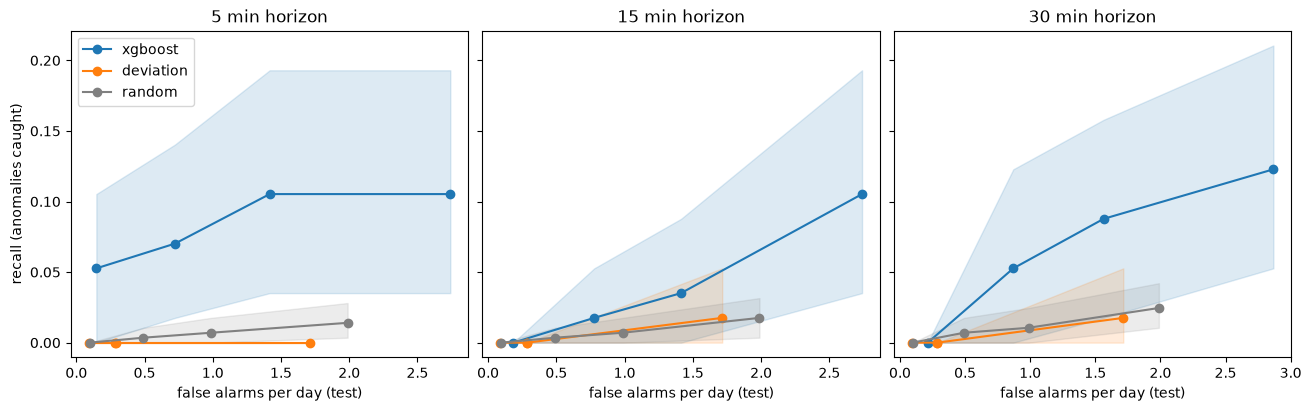

In [4]:
# Recall vs false alarms per day on the test years, with 95% bootstrap intervals over anomalies
fig, axes = plt.subplots(1, len(HORIZONS), figsize=(13, 4), sharey=True, layout='constrained')
for ax, h in zip(axes, HORIZONS):
    for m, c in [('xgboost', 'tab:blue'), ('deviation', 'tab:orange'), ('random', 'gray')]:
        r = result.loc[(m, h)]
        ax.plot(r.test_far_per_day, r.recall, 'o-', color=c, label=m)
        ax.fill_between(r.test_far_per_day, r.recall_lo, r.recall_hi, color=c, alpha=0.15)
    ax.set(title=f'{h} min horizon', xlabel='false alarms per day (test)')
axes[0].set_ylabel('recall (anomalies caught)')
axes[0].legend()
plt.show()

In [5]:
# Per class, for the two classes with enough test events
by_class = pd.concat({m: pool(per_event[m][per_event[m].Class.isin(MAIN_CLASSES)], summary[m], by=['Class'])
                      for m in results}, names=['model'])
by_class.recall.unstack(['model', 'Class']).round(3)

model              xgboost         deviation        
Class              class_3 class_7   class_3 class_7
horizon far_target                                  
5       0.1          0.000   0.130       0.0     0.0
        0.5          0.000   0.174       0.0     0.0
        1.0          0.000   0.217       0.0     0.0
        2.0          0.000   0.217       0.0     0.0
15      0.1          0.000   0.000       0.0     0.0
        0.5          0.042   0.000       0.0     0.0
        1.0          0.042   0.043       0.0     0.0
        2.0          0.083   0.130       0.0     0.0
30      0.1          0.000   0.000       0.0     0.0
        0.5          0.000   0.087       0.0     0.0
        1.0          0.000   0.174       0.0     0.0
        2.0          0.083   0.174       0.0     0.0

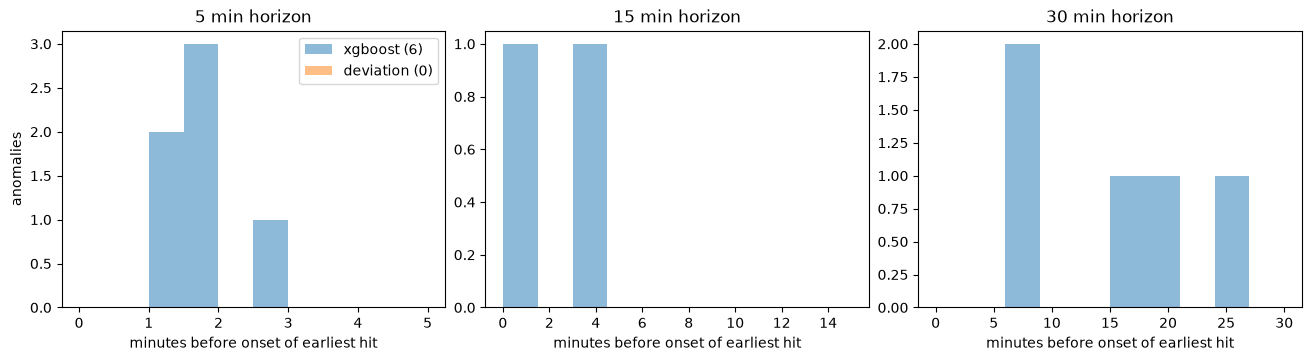

count  25%   50%   75%
model   horizon                        
xgboost 5          6.0  1.2   1.5   1.5
        15         2.0  1.3   2.1   2.9
        30         5.0  8.7  17.3  19.2

In [6]:
# Lead time of caught anomalies at 1 false alarm per day. Catches bunched near 0 min look like late labels,
# not warning signs; catches spread across the horizon are real advance warning.
caught = pd.concat(per_event, names=['model', 'ID']).reset_index().query('far_target == 1 and caught')
fig, axes = plt.subplots(1, len(HORIZONS), figsize=(13, 3.5), layout='constrained')
for ax, h in zip(axes, HORIZONS):
    for m, c in [('xgboost', 'tab:blue'), ('deviation', 'tab:orange')]:
        lead = caught[(caught.model == m) & (caught.horizon == h)].lead_min
        ax.hist(lead, bins=np.linspace(0, h, 11), color=c, alpha=0.5, label=f'{m} ({len(lead)})')
    ax.set(title=f'{h} min horizon', xlabel='minutes before onset of earliest hit')
axes[0].set_ylabel('anomalies')
axes[0].legend()
plt.show()
caught.groupby(['model', 'horizon']).lead_min.describe()[['count', '25%', '50%', '75%']].round(1)